1. What is Simple Linear Regression?
- Simple Linear Regression (SLR) is a statistical and machine-learning method that models the relationship between one independent variable (X, the predictor) and one dependent variable (Y, the target) by fitting a straight line to the data. The model is used to understand how Y changes when X changes and to predict the value of Y for a new X.

  Y = mX + c

  Here m is the slope and c is the intercept. Example: predicting the marks of a student (Y) from the number of hours studied (X).

2.  What are the key assumptions of Simple Linear Regression?
-   For the estimates and the predictions to be reliable, SLR assumes the       following:
    Linearity: the relationship between X and Y is linear.
  
    Independence: the observations (and their errors) are independent of each other, e.g. no autocorrelation in time-series data.
    
    Homoscedasticity: the variance of the residuals is constant for all values of X.
    
    Normality of residuals: the errors are approximately normally distributed (needed mainly for confidence intervals and hypothesis tests).
  
    No significant outliers or high-leverage points: extreme values can pull the line strongly.

3.  What does the coefficient m represent in the equation Y = mX + c?
- The coefficient m is the slope of the regression line. It shows the average change in Y for a one-unit increase in X. If m is positive, Y increases as X increases; if m is negative, Y decreases as X increases; and if m is close to zero, X has little linear effect on Y. For example, if m = 6.7 in a marks-versus-hours model, each extra hour of study is associated with about 6.7 more marks.

4.  What does the intercept c represent in the equation Y = mX + c?
- The intercept c is the predicted value of Y when X = 0, i.e. the point where the line crosses the Y-axis. It is the baseline value of the target when the predictor has no contribution. Sometimes it has a practical meaning (for example a fixed charge in a taxi fare), but when X = 0 is not possible or outside the range of the data (for example height = 0), the intercept is just a mathematical constant that positions the line.






In [2]:
# 5. How do we calculate the slope m in Simple Linear Regression?
"""
The slope is calculated with the least squares formula:
 m = Σ(Xi − X̄)(Yi − Ȳ) / Σ(Xi - X̄)²
This is the same as m = Cov(X, Y) / Var(X), or m = r × (SD of Y / SD of X), where r is the correlation coefficient.
Once m is known, the intercept is c = Ȳ − m·X̄. The code below calculates both by hand and checks them with scikit-learn.
"""
import numpy as np
from sklearn.linear_model import LinearRegression

# Study hours (X) and exam marks (Y)
X = np.array([1, 2, 3, 4, 5, 6, 7, 8])
Y = np.array([35, 42, 50, 55, 62, 68, 77, 82])

# Slope and intercept using the formula
x_mean, y_mean = X.mean(), Y.mean()
m = np.sum((X - x_mean) * (Y - y_mean)) / np.sum((X - x_mean) ** 2)
c = y_mean - m * x_mean
print("Slope m      :", round(m, 3))
print("Intercept c  :", round(c, 3))

# R-squared
Y_pred = m * X + c
r2 = 1 - np.sum((Y - Y_pred) ** 2) / np.sum((Y - y_mean) ** 2)
print("R-squared    :", round(r2, 4))

# Check with scikit-learn
model = LinearRegression().fit(X.reshape(-1, 1), Y)
print("sklearn m, c :", round(model.coef_[0], 3), round(model.intercept_, 3))
print("Prediction for 9 hours:", round(model.predict([[9]])[0], 1))


Slope m      : 6.726
Intercept c  : 28.607
R-squared    : 0.9975
sklearn m, c : 6.726 28.607
Prediction for 9 hours: 89.1


6.  What is the purpose of the least squares method in Simple Linear Regression ?
- The least squares method is used to find the best-fitting line. For any line, the difference between the actual value and the predicted value of every point is called the residual (error). Least squares chooses the values of m and c that minimise the sum of the squares of these residuals:
minimise  SSE = Σ (Yi − (mXi + c))²
The errors are squared so that positive and negative errors do not cancel each other and larger errors are penalised more. The method gives a unique solution with a simple closed-form formula, and under the standard assumptions it gives the best linear unbiased estimates of the coefficients.

7.  How is the coefficient of determination (R²) interpreted in Simple Linear Regression ?
- R² tells what proportion of the variation in Y is explained by X through the model:
R² = 1 − SSE / SST
It lies between 0 and 1. An R² of 0.85 means that 85% of the variability in the target is explained by the model and the remaining 15% is due to other factors or random noise. R² = 1 means a perfect fit and R² close to 0 means the model explains almost nothing. In SLR, R² is also equal to the square of the correlation coefficient (r²). A high R² does not by itself prove that the model is good or that X causes Y (see Question 18).

8.  What is Multiple Linear Regression?
- Multiple Linear Regression (MLR) models the relationship between one dependent variable and two or more independent variables. The equation is:
Y = b0 + b1X1 + b2X2 + … + bnXn + ε
Each coefficient bi shows the change in Y for a one-unit change in Xi while the other variables are held constant. Example: predicting the price of a house from its area, number of rooms and age.

9.  What is the main difference between Simple and Multiple Linear Regression?
- The main difference is the number of predictors. Simple linear regression uses only one independent variable and gives a line, while multiple linear regression uses two or more independent variables and gives a plane or hyperplane. In MLR each coefficient is interpreted after controlling for the other variables, we need to check problems like multicollinearity, and we use adjusted R² instead of R² to compare models. MLR is usually more realistic because real-world outcomes depend on many factors.

10. What are the key assumptions of Multiple Linear Regression?
- Linearity: the relationship between the target and each predictor is linear.
  Independence of errors: residuals are not correlated with each other (checked with the Durbin-Watson test).
  
  Homoscedasticity: residuals have constant variance.

  Normality of residuals: errors are approximately normal (check with a Q-Q plot).

  No (or low) multicollinearity: predictors should not be highly correlated with each other (checked with VIF).

  No influential outliers: and the number of observations should be sufficiently larger than the number of predictors.

11. What is heteroscedasticity, and how does it affect the results of a Multiple Linear Regression model?
- Heteroscedasticity means that the variance of the residuals is not constant; it changes with the fitted values or with one of the predictors (for example, errors becoming larger for high-income households). It is the opposite of homoscedasticity.

  Effects on the model:
  
  The coefficient estimates remain unbiased, but they are no longer the most efficient (not BLUE).
  
  The standard errors become wrong (usually underestimated), so t-tests, p-values and confidence intervals are unreliable; a variable may look significant when it is not.
  
  Prediction intervals are too narrow in some regions and too wide in others.
  It can be handled by transforming the target (log or square-root), using weighted least squares, using robust (heteroscedasticity-consistent) standard errors, or adding missing variables. See Question 20 for how to detect it.

12. How can you improve a Multiple Linear Regression model with high multicollinearity?
- Multicollinearity means that the predictors are strongly correlated, which makes the coefficients unstable and hard to interpret (large standard errors, signs that change when data changes). It is detected with the correlation matrix or the Variance Inflation Factor (VIF > 5 or 10 is a warning). It can be improved by:

  Removing one of the highly correlated variables.
  
  Combining correlated variables into one (for example by averaging) or using PCA to create uncorrelated components.
  
  Using regularisation: Ridge regression shrinks the correlated coefficients, and Lasso can drop some of them.
  
  Collecting more data, or centring the variables when the problem is caused by polynomial or interaction terms.

13. What are some common techniques for transforming categorical variables for use in regression models?
- Regression models need numbers, so categorical variables must be encoded:
  
  One-hot / dummy encoding: creates a 0/1 column for each category. For k categories we keep k − 1 columns (drop_first) to avoid the dummy variable trap. Used for nominal data such as city or colour.

  Ordinal (label) encoding: assigns ordered integers such as Small = 1, Medium = 2, Large = 3. Used only when the categories have a natural order.
  
  Target / mean encoding: replaces the category with the mean of the target for that category; useful for high-cardinality columns but needs care to avoid data leakage.
  
  Binary or frequency encoding: compact alternatives when there are many categories.

14. What is the role of interaction terms in Multiple Linear Regression?
- An interaction term is the product of two (or more) predictors, such as X1 × X2. It is added when the effect of one variable on the target depends on the level of another variable. Without it, the model assumes that every predictor acts independently (additive effects). For example, the effect of advertising spend on sales may be larger when a discount is also offered. The coefficient of the interaction term shows how much the slope of one variable changes for each unit of the other. Adding it can improve the fit, but it also makes the interpretation harder and increases multicollinearity, so variables are often centred first.

15. How can the interpretation of intercept differ between Simple and Multiple Linear Regression?
- In simple linear regression the intercept is the expected value of Y when the single predictor X is zero. In multiple linear regression the intercept is the expected value of Y when all the predictors are zero at the same time. This is a much less likely situation (for example a house with zero area, zero rooms and zero age), so the intercept is often not meaningful by itself and mainly acts as an adjustment term. Its interpretation becomes clearer when the variables are centred, because then the intercept represents the predicted Y for an average observation.

16. What is the significance of the slope in regression analysis, and how does it affect predictions?
- The slope shows the strength and direction of the relationship between a predictor and the target. Its sign tells whether the relationship is positive or negative, and its size tells how much Y changes for each unit change in X (in MLR, holding the other variables constant). Statistically, a slope is significant if its p-value is small (usually below 0.05), which means that it is unlikely to be zero in the population.
For predictions, the slope decides how sensitive the predicted value is to the input. A steeper slope means that a small change in X causes a large change in the prediction, so any error in the slope or in X is magnified. A slope near zero means that the variable adds almost nothing to the prediction.

17. How does the intercept in a regression model provide context for the relationship between variables?
- The intercept gives the starting point or baseline of the relationship. It tells where the regression line begins when all the predictors are zero, and the slopes then describe how the prediction moves away from this baseline. For example, in a model for electricity bill = 150 + 6 × units, the intercept 150 is the fixed monthly charge that the customer pays even with zero usage, and 6 is the cost of each unit. Without the intercept the line would be forced to pass through the origin, which can bias the slopes if the data does not behave like that. However, if X = 0 lies outside the observed data range, the intercept is an extrapolation and should not be over-interpreted.

18. What are the limitations of using R² as a sole measure of model performance?- It never decreases when predictors are added: even useless variables increase R², which encourages overfitting. Adjusted R² partly fixes this.
  
    It does not show overfitting: a high R² on training data can still give poor results on new data, so test-set metrics are needed.
  
    It does not show bias or wrong model form: a curved relationship can still give a high R² with a linear model, so residual plots are needed.

    It says nothing about the size of errors: RMSE or MAE give the error in the units of the target.

    It is sensitive to outliers and the range of X, and it does not prove causation.
    So R² should be used together with adjusted R², RMSE/MAE, cross-validation and residual analysis.

19. How would you interpret a large standard error for a regression coefficient?
- The standard error measures how much the estimated coefficient would vary from sample to sample. A large standard error means that the estimate is imprecise and unstable: the true coefficient could be far from the estimated value. The t-statistic (coefficient / standard error) becomes small, the p-value becomes large, and the confidence interval becomes wide and often includes zero, so we cannot say that the variable has a real effect.
Common causes are multicollinearity, a small sample size, a small variation in the predictor, or high noise in the data (large residual variance). It can be reduced by collecting more data, removing or combining correlated predictors, or using regularisation.




Homoscedastic (good) -> corr(|residual|, fitted) = -0.06
Heteroscedastic (funnel shape) -> corr(|residual|, fitted) = 0.47


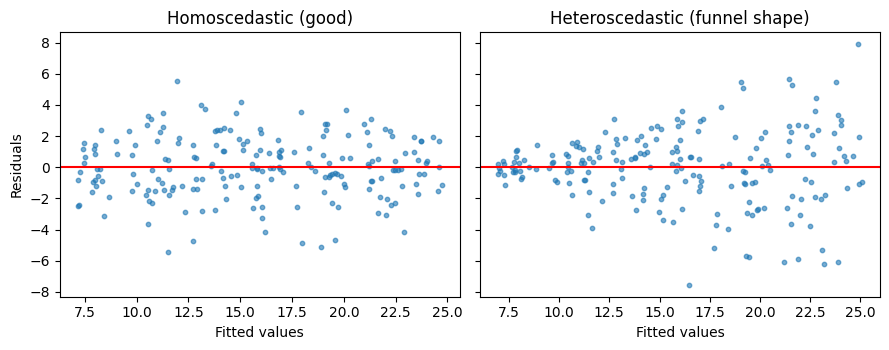

'\nThe right plot shows the typical funnel shape; \nthe correlation between the absolute residual and the fitted values is high (0.47) compared with the constant-variance case (about 0). \nIt is important to address because it makes standard errors, p-values and confidence intervals unreliable, \nso wrong conclusions about the significance of variables can be drawn. Remedies are a log or Box-Cox transformation of Y, \nweighted least squares, or robust standard errors.\n'

In [3]:
"""
20. How can heteroscedasticity be identified in residual plots, and why is it important to address it?
- Plot the residuals on the Y-axis against the fitted values (or against a predictor) on the X-axis.
If the variance is constant, the points form a random, even band around zero. If heteroscedasticity is present,
the points form a funnel or cone shape (spread increasing or decreasing), or show a clear curve.
It can also be confirmed with formal tests such as the Breusch-Pagan or White test, where a small p-value indicates heteroscedasticity.
"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(5)
x = rng.uniform(1, 10, 200).reshape(-1, 1)
y_const = 5 + 2 * x.ravel() + rng.normal(0, 2, 200)               # constant variance
y_hetero = 5 + 2 * x.ravel() + rng.normal(0, 0.4 * x.ravel(), 200)  # variance grows with x

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for a, y, title in zip(ax, [y_const, y_hetero], ['Homoscedastic (good)', 'Heteroscedastic (funnel shape)']):
    model = LinearRegression().fit(x, y)
    fitted = model.predict(x)
    resid = y - fitted
    a.scatter(fitted, resid, s=10, alpha=0.6)
    a.axhline(0, color='red')
    a.set_title(title)
    a.set_xlabel('Fitted values')
    print(title, "-> corr(|residual|, fitted) = %.2f" % np.corrcoef(np.abs(resid), fitted)[0, 1])
ax[0].set_ylabel('Residuals')
plt.tight_layout()
plt.savefig('q20_resid.png', dpi=130)
plt.show()


In [4]:
"""
21. What does it mean if a Multiple Linear Regression model has a high R² but low adjusted R²?
->
 It means that the model contains predictors that do not really help to explain the target.
R² always increases when a variable is added, even if the variable is just noise, but adjusted R² penalises the number of predictors:
  Adjusted R² = 1 − (1 − R²)(n − 1) / (n − p − 1)
When the gap between the two is large, the model is probably overfitted (too many predictors for the amount of data),
and it will perform worse on new data. The solution is to remove the irrelevant variables (feature selection, Lasso,
stepwise selection), get more data, and validate with a test set or cross-validation.
"""
import numpy as np
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(0)
n = 40
x_real = rng.normal(size=(n, 1))
y = 4 * x_real.ravel() + rng.normal(0, 2, n)

def r2_and_adj(X, y):
    n, p = X.shape
    r2 = LinearRegression().fit(X, y).score(X, y)
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return r2, adj

# model A: 1 useful predictor ; model B: same predictor + 25 useless noise columns
X_a = x_real
X_b = np.hstack([x_real, rng.normal(size=(n, 30))])
for name, X in [('1 useful predictor', X_a), ('1 useful + 30 noise predictors', X_b)]:
    r2, adj = r2_and_adj(X, y)
    print("%-32s R2 = %.3f   Adjusted R2 = %.3f" % (name, r2, adj))


1 useful predictor               R2 = 0.661   Adjusted R2 = 0.652
1 useful + 30 noise predictors   R2 = 0.941   Adjusted R2 = 0.710


In [5]:
"""
22. Why is it important to scale variables in Multiple Linear Regression?
->
Ordinary least squares predictions do not change with scaling, but scaling is still important for several reasons:
•	It makes the coefficients comparable. When one variable is in lakhs (income) and another in years (age), the raw coefficients cannot be compared; after standardisation they show the relative importance.
•	It is necessary for regularised models (Ridge, Lasso, Elastic Net), because the penalty is applied equally to all coefficients and unfairly shrinks variables with small scales.
•	It helps gradient-descent based optimisation to converge faster and more stably.
•	It reduces numerical problems and the multicollinearity caused by interaction and polynomial terms.
Common methods are standardisation (z-score, StandardScaler) and min-max scaling. The scaler must be fitted on the training data only.
"""
import numpy as np
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(2)
n = 200
income = rng.normal(50000, 15000, n)       # large scale
age = rng.normal(35, 8, n)                 # small scale
y = 0.002 * income + 1.5 * age + rng.normal(0, 5, n)
X = np.column_stack([income, age])

lr = LinearRegression().fit(X, y)
print("OLS coefficients, raw data   :", lr.coef_.round(4), "(income, age) - not comparable")
print("Ridge (alpha=1e5), raw data  :", Ridge(alpha=1e5).fit(X, y).coef_.round(4), "- penalty hits 'age' unfairly")

Xs = StandardScaler().fit_transform(X)
print("OLS coefficients, scaled data:", LinearRegression().fit(Xs, y).coef_.round(3), "- directly comparable")
print("Ridge (alpha=1e5), scaled    :", Ridge(alpha=1e5).fit(Xs, y).coef_.round(3), "- both shrunk in the same proportion")



OLS coefficients, raw data   : [0.002  1.4987] (income, age) - not comparable
Ridge (alpha=1e5), raw data  : [0.002  0.1857] - penalty hits 'age' unfairly
OLS coefficients, scaled data: [28.988 12.604] - directly comparable
Ridge (alpha=1e5), scaled    : [0.058 0.026] - both shrunk in the same proportion


23. What is polynomial regression?
- Polynomial regression is a form of regression in which the relationship between the independent variable X and the dependent variable Y is modelled as an n-th degree polynomial. It lets the model fit a curve instead of a straight line. Even though the fitted curve is non-linear in X, the model is still linear in the coefficients, so it can be solved with ordinary least squares. Example: the relationship between years of experience and salary, or speed and braking distance.

24. How does polynomial regression differ from linear regression?
- Aspect	Linear regression	Polynomial regression
Equation	Y = b0 + b1X	Y = b0 + b1X + b2X² + … + bnXⁿ
Shape of the fit	Straight line	Curve (can bend several times)
Relationship captured	Only linear	Non-linear
Flexibility / risk	Simple, may underfit curved data	More flexible, but high degrees can overfit
Extra features	None	Powers of X are added as new features
Interpretability	Easy	Harder as the degree increases

25. When is polynomial regression used?
- It is used when a scatter plot or residual plot shows a curved pattern that a straight line cannot capture. Typical situations are:
•	Growth or decay patterns, such as population growth, spread of disease or depreciation of a machine.
•	Relationships with a turning point, such as crop yield versus fertiliser amount (rises, then falls).
•	Physics and engineering data like projectile motion, braking distance versus speed, or temperature versus pressure.
•	Economics and business data, such as salary versus experience or sales versus advertising when there are diminishing returns.

26. What is the general equation for polynomial regression?
- Y = b0 + b1X + b2X² + b3X³ + … + bnXⁿ + ε
Here n is the degree of the polynomial, b0 is the intercept, b1 … bn are the coefficients that are learned by least squares, and ε is the random error. For degree 2 (quadratic) it becomes Y = b0 + b1X + b2X², and for degree 3 (cubic) it adds the X³ term.

27. Can polynomial regression be applied to multiple variables?
- Yes. With several predictors, polynomial features are created for each variable as well as cross-product (interaction) terms between them. For two variables X1 and X2 and degree 2, the model is:
Y = b0 + b1X1 + b2X2 + b3X1² + b4X2² + b5X1X2
In scikit-learn this is done with PolynomialFeatures(degree=2) on the full feature matrix, followed by LinearRegression. The number of features grows very fast with the number of variables and the degree, so regularisation (Ridge/Lasso) and feature scaling are usually needed.

28. What are the limitations of polynomial regression?
- Overfitting: high-degree polynomials follow the noise in the training data and generalise poorly.
•	Poor extrapolation: outside the range of the data the curve can shoot up or down wildly.
•	Sensitive to outliers: a few extreme points can change the curve a lot.
•	Choice of degree: a suitable degree must be selected by validation, and there is no simple rule.
•	Multicollinearity: X, X², X³ are highly correlated, which makes the coefficients unstable unless the data is scaled or centred.
•	Hard to interpret and computationally heavy when the degree or the number of variables is large.


In [6]:
"""
29. What methods can be used to evaluate model fit when selecting the degree of a polynomial?
->
•	Train/test split: compare the training and test R² or RMSE. A large gap indicates overfitting.
•	k-fold cross-validation: choose the degree with the lowest average validation error.
•	Adjusted R², AIC and BIC: these penalise model complexity, so higher degrees are accepted only if they improve the fit enough.
•	Residual plots and visual inspection: the residuals should be random with no pattern.
•	Learning / validation curves: plot the error against the degree and pick the point where the validation error is lowest (bias-variance trade-off).
"""

import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import r2_score

rng = np.random.default_rng(10)
X = np.sort(rng.uniform(-3, 3, 80)).reshape(-1, 1)
y = 1 + 2 * X.ravel() - 1.5 * X.ravel() ** 2 + 0.4 * X.ravel() ** 3 + rng.normal(0, 2, 80)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=1)

print("Degree | Train R2 | Test R2 | 5-fold CV RMSE")
for d in range(1, 9):
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X_tr, y_tr)
    cv_rmse = -cross_val_score(model, X_tr, y_tr, cv=5, scoring='neg_root_mean_squared_error').mean()
    print("%6d | %8.3f | %7.3f | %.3f" % (d, r2_score(y_tr, model.predict(X_tr)),
                                         r2_score(y_te, model.predict(X_te)), cv_rmse))


Degree | Train R2 | Test R2 | 5-fold CV RMSE
     1 |    0.676 |   0.202 | 3.741
     2 |    0.838 |   0.735 | 2.746
     3 |    0.912 |   0.818 | 2.068
     4 |    0.912 |   0.815 | 2.094
     5 |    0.913 |   0.825 | 2.126
     6 |    0.913 |   0.818 | 2.219
     7 |    0.913 |   0.819 | 2.259
     8 |    0.914 |   0.831 | 2.387


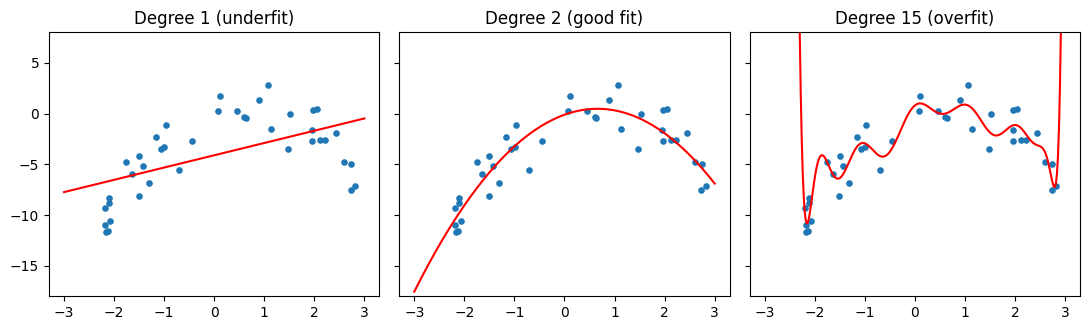

In [7]:
"""
30. Why is visualization important in polynomial regression?
Answer:
Visualisation is important because polynomial regression is mainly about the shape of the curve. A plot of the data and the fitted curve helps to:
•	see whether the relationship is really curved before choosing polynomial regression;
•	compare different degrees and spot underfitting (a line that is too simple) or overfitting (a wiggly curve that chases the noise);
•	detect outliers, and see unrealistic behaviour at the ends of the range, where polynomials tend to explode;
•	communicate the result easily to non-technical people.
"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(10)
X = np.sort(rng.uniform(-3, 3, 40)).reshape(-1, 1)
y = 1 + 2 * X.ravel() - 1.5 * X.ravel() ** 2 + rng.normal(0, 2, 40)
grid = np.linspace(-3, 3, 300).reshape(-1, 1)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for a, d, t in zip(ax, [1, 2, 15], ['Degree 1 (underfit)', 'Degree 2 (good fit)', 'Degree 15 (overfit)']):
    model = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(X, y)
    a.scatter(X, y, s=14)
    a.plot(grid, model.predict(grid), color='red')
    a.set_title(t)
    a.set_ylim(-18, 8)
plt.tight_layout()
plt.savefig('q30_degrees.png', dpi=130)
plt.show()


Coefficients : [-0.635  1.28 ]
Intercept    : 29.9
R2 score     : 0.9999
RMSE         : 0.39
Predicted salary for 11 years: 177.8


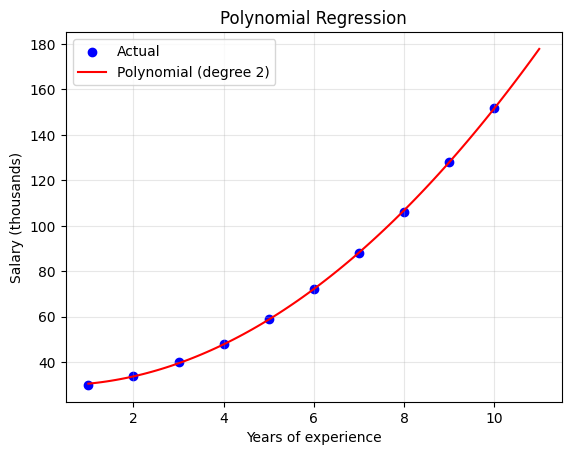

In [8]:
"""
31. How is polynomial regression implemented in Python?
->
It is implemented in three steps: (1) generate polynomial features with PolynomialFeatures from sklearn.preprocessing,
(2) fit a LinearRegression model on these features, and
(3) predict and evaluate (the two steps can also be combined using make_pipeline).
"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Sample data: salary vs. years of experience (non-linear growth)
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([30, 34, 40, 48, 59, 72, 88, 106, 128, 152])      # in thousands

# 1) create polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# 2) fit a linear model on the new features
model = LinearRegression().fit(X_poly, y)
y_pred = model.predict(X_poly)

print("Coefficients :", model.coef_.round(3))
print("Intercept    :", round(model.intercept_, 3))
print("R2 score     :", round(r2_score(y, y_pred), 4))
print("RMSE         :", round(np.sqrt(mean_squared_error(y, y_pred)), 3))
print("Predicted salary for 11 years:", round(model.predict(poly.transform([[11]]))[0], 1))

# 3) visualise
grid = np.linspace(1, 11, 100).reshape(-1, 1)
plt.scatter(X, y, color='blue', label='Actual')
plt.plot(grid, model.predict(poly.transform(grid)), color='red', label='Polynomial (degree 2)')
plt.xlabel('Years of experience')
plt.ylabel('Salary (thousands)')
plt.title('Polynomial Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('q31_poly.png', dpi=130)
plt.show()
